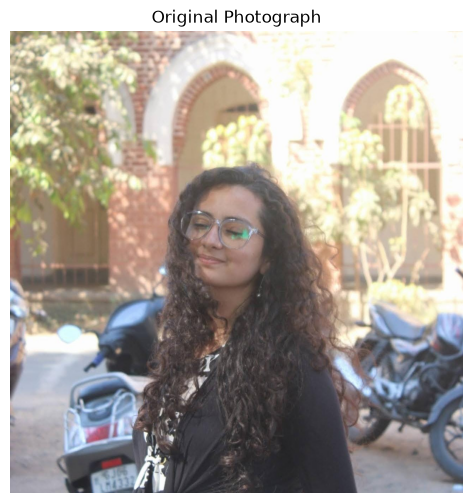

Image loaded successfully!
Image dimensions (height, width, channels): (1304, 1279, 3)
Data type: uint8


In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Define the image path
image_path = Path("../data/images/original.jpeg")

# Load the original image
image = cv2.imread(str(image_path))

# Check whether the image loaded successfully
if image is None:
    raise FileNotFoundError(
        f"Image not found or could not be opened: {image_path.resolve()}"
    )

# OpenCV loads images in BGR format; Matplotlib expects RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display the original image
plt.figure(figsize=(8, 6))
plt.imshow(image_rgb)
plt.title("Original Photograph")
plt.axis("off")
plt.show()

# Display basic image information
print("Image loaded successfully!")
print("Image dimensions (height, width, channels):", image.shape)
print("Data type:", image.dtype)


2. Gaussian Filter

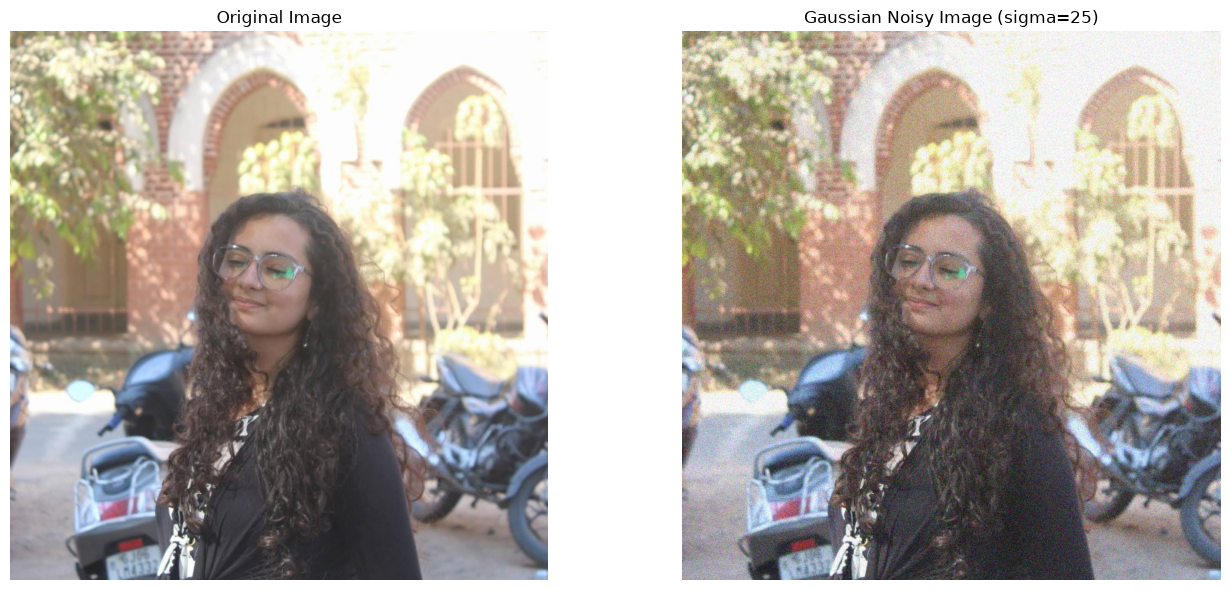

In [9]:
# Step 1: Set the noise parameters
mean = 0
sigma = 25

# Step 2: Convert the original image to float
image_float = image.astype(np.float32)

# Step 3: Generate random Gaussian noise
np.random.seed(42)  # Makes the experiment reproducible
gaussian_noise = np.random.normal(
    mean, sigma, image.shape
).astype(np.float32)

# Step 4: Add noise to the original image
noisy_image = image_float + gaussian_noise

# Step 5: Clip pixel values and convert back to uint8
noisy_image = np.clip(noisy_image, 0, 255).astype(np.uint8)

# Step 6: Convert BGR to RGB for display
noisy_image_rgb = cv2.cvtColor(
    noisy_image, cv2.COLOR_BGR2RGB
)

# Step 7: Display original and noisy images side by side
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(noisy_image_rgb)
plt.title(f"Gaussian Noisy Image (sigma={sigma})")
plt.axis("off")

plt.tight_layout()
plt.show()


In [10]:

from pathlib import Path

output_dir = Path("../outputs/restoration")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "gaussian_noisy.png"

success = cv2.imwrite(str(output_path), noisy_image)

if success:
    print(f"Noisy image saved at: {output_path.resolve()}")
else:
    raise IOError("Could not save the noisy image.")


Noisy image saved at: C:\Users\HP\computer-vision-toolkit\outputs\restoration\gaussian_noisy.png


3. Salt-and-Pepper Noise Generation

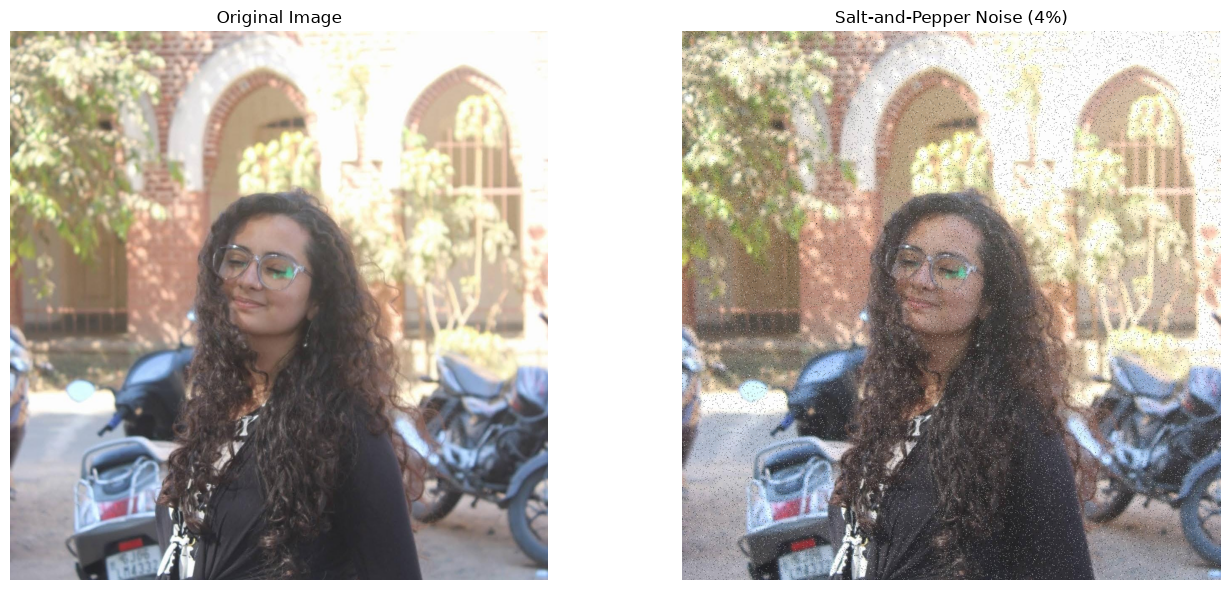

In [11]:
# Step 1: Create a copy of the original image
sp_noisy_image = image.copy()

# Step 2: Set the noise amount
noise_amount = 0.04  # 4% of all pixels

# Step 3: Calculate the number of pixels to modify
total_pixels = image.shape[0] * image.shape[1]
num_noisy_pixels = int(noise_amount * total_pixels)

# Step 4: Randomly select pixel coordinates
np.random.seed(42)

rows = np.random.randint(0, image.shape[0], num_noisy_pixels)
cols = np.random.randint(0, image.shape[1], num_noisy_pixels)

# Step 5: Split selected pixels between salt and pepper
num_salt = num_noisy_pixels // 2

# White pixels (salt)
sp_noisy_image[rows[:num_salt], cols[:num_salt]] = 255

# Black pixels (pepper)
sp_noisy_image[rows[num_salt:], cols[num_salt:]] = 0

# Step 6: Convert BGR to RGB for display
sp_noisy_image_rgb = cv2.cvtColor(
    sp_noisy_image, cv2.COLOR_BGR2RGB
)

# Step 7: Display original and noisy images
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sp_noisy_image_rgb)
plt.title("Salt-and-Pepper Noise (4%)")
plt.axis("off")

plt.tight_layout()
plt.show()


In [12]:
output_dir = Path("../outputs/restoration")
output_dir.mkdir(parents=True, exist_ok=True)

sp_output_path = output_dir / "salt_pepper_noisy.png"

success = cv2.imwrite(str(sp_output_path), sp_noisy_image)

if success:
    print(f"Salt-and-pepper image saved at: {sp_output_path.resolve()}")
else:
    raise IOError("Could not save the salt-and-pepper noisy image.")


Salt-and-pepper image saved at: C:\Users\HP\computer-vision-toolkit\outputs\restoration\salt_pepper_noisy.png


In [13]:
# Experiment 3: Restore noisy images using Gaussian and Median filters

# 1. Restore the Gaussian-noisy image
gaussian_restored = cv2.GaussianBlur(noisy_image, (5, 5), 0)
median_restored_gaussian = cv2.medianBlur(noisy_image, 5)

# 2. Restore the salt-and-pepper-noisy image
gaussian_restored_sp = cv2.GaussianBlur(sp_noisy_image, (5, 5), 0)
median_restored_sp = cv2.medianBlur(sp_noisy_image, 5)

print("Image restoration completed successfully!")


Image restoration completed successfully!


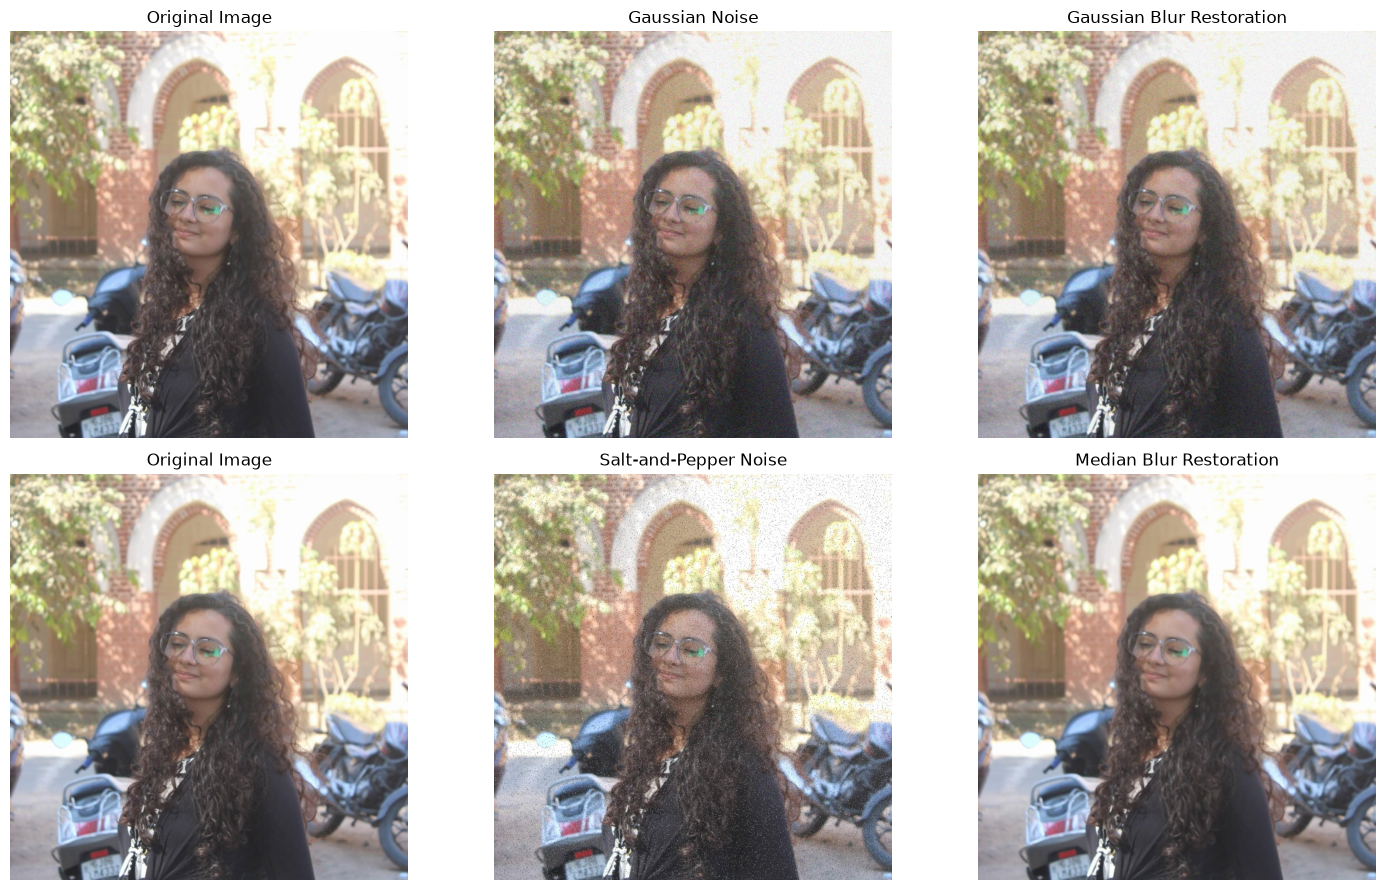

In [14]:

# Display the restored images

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

images_to_display = [
    (image, "Original Image"),
    (noisy_image, "Gaussian Noise"),
    (gaussian_restored, "Gaussian Blur Restoration"),
    (image, "Original Image"),
    (sp_noisy_image, "Salt-and-Pepper Noise"),
    (median_restored_sp, "Median Blur Restoration"),
]

for ax, (img, title) in zip(axes.flat, images_to_display):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [15]:

# Save restored images

output_dir = Path("../outputs/restoration")
output_dir.mkdir(parents=True, exist_ok=True)

restored_images = {
    "gaussian_blur_restored.png": gaussian_restored,
    "median_blur_gaussian_noise.png": median_restored_gaussian,
    "gaussian_blur_salt_pepper.png": gaussian_restored_sp,
    "median_blur_salt_pepper.png": median_restored_sp,
}

for filename, restored_img in restored_images.items():
    save_path = output_dir / filename
    success = cv2.imwrite(str(save_path), restored_img)
    print(f"{filename}: {'Saved successfully' if success else 'Save failed'}")


gaussian_blur_restored.png: Saved successfully
median_blur_gaussian_noise.png: Saved successfully
gaussian_blur_salt_pepper.png: Saved successfully
median_blur_salt_pepper.png: Saved successfully


In [16]:

from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Store all four restoration results
restoration_results = {
    "Gaussian noise + Gaussian blur": gaussian_restored,
    "Gaussian noise + Median blur": median_restored_gaussian,
    "Salt-and-pepper noise + Gaussian blur": gaussian_restored_sp,
    "Salt-and-pepper noise + Median blur": median_restored_sp,
}

# Calculate metrics against the original image
metrics = []

for method, restored_img in restoration_results.items():
    original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    restored_rgb = cv2.cvtColor(restored_img, cv2.COLOR_BGR2RGB)

    psnr_value = peak_signal_noise_ratio(
        original_rgb, restored_rgb, data_range=255
    )

    ssim_value = structural_similarity(
        original_rgb,
        restored_rgb,
        channel_axis=2,
        data_range=255
    )

    metrics.append((method, psnr_value, ssim_value))

# Display results
print(f"{'Restoration Method':<43} {'PSNR (dB)':>12} {'SSIM':>10}")
print("-" * 67)

for method, psnr_value, ssim_value in metrics:
    print(f"{method:<43} {psnr_value:>12.2f} {ssim_value:>10.4f}")


Restoration Method                             PSNR (dB)       SSIM
-------------------------------------------------------------------
Gaussian noise + Gaussian blur                     30.55     0.7486
Gaussian noise + Median blur                       31.61     0.7685
Salt-and-pepper noise + Gaussian blur              29.39     0.7022
Salt-and-pepper noise + Median blur                40.64     0.9744
